# ch02_1. MNIST MLP 숫자 분류

## 실제 손글씨 숫자 이미지 학습하기

## 개요

- `torchvision.datasets.MNIST`로 실제 MNIST 데이터를 불러옵니다.
- 실제 이미지의 정답·예측값·클래스 확률을 확인합니다.

## 1. 전체 실습 흐름

```text
MNIST 다운로드
→ Tensor 변환
→ 훈련·검증 데이터 분리
→ DataLoader 구성
→ MLP 모델 생성
→ CrossEntropyLoss + Adam 설정
→ 5 Epoch 학습
→ 매 Epoch 검증
→ 테스트 최종 평가
→ 실제 이미지 예측
```

 API의 역할은 이미 확인했습니다.
 **실제 이미지 데이터로 전체 흐름을 실행하는 것**이 핵심입니다.

## 2. 라이브러리와 실행 장치

- GPU를 사용할 수 있으면 CUDA(쿠다, 엔비디아 GPU 연산 환경)를 사용합니다.
- GPU가 없으면 CPU를 사용합니다.
- 모델과 입력 Tensor는 반드시 같은 장치에 있어야 합니다.

In [ ]:
import math   #sqrt(), ceil(), floor() 등 사용
import torch  #Pytorch 핵심 라이브러리
from torch import nn    #Pytorch nn(신경망) 모듈
#data load, batch(배치, 묶음), random_split : 데이터 무작위
from torch.utils.data import DataLoader, random_split
#이미지 딥러닝에 사용하는 라이브러리 (MNIST, CIFAR10)
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu")

print("사용 장치:", device)

사용 장치: cuda


## 3. MNIST 데이터 불러오기

MNIST는 다음과 같이 구성됩니다.

- 훈련 데이터: 60,000개
- 테스트 데이터: 10,000개
- 이미지 크기: 28×28
- 채널 수: 1개
- 클래스: 숫자 0~9

`transforms.ToTensor()`는 이미지를 Tensor로 변환하고 픽셀값을 0과 1 사이로 바꿉니다.

In [17]:
transform = transforms.ToTensor()

full_train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    transform=transform,
    download=True,
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    transform=transform,
    download=True,
)

print("전체 훈련 데이터:", len(full_train_dataset))
print("테스트 데이터:", len(test_dataset))

전체 훈련 데이터: 60000
테스트 데이터: 10000


## 4. 이미지 한 장 확인

MNIST 이미지 한 장의 shape는 `[1, 28, 28]`입니다.

- `1`: 흑백 채널
- `28`: 세로 픽셀 수
- `28`: 가로 픽셀 수

이미지 shape: torch.Size([1, 28, 28])
정답 숫자: 5
픽셀값 범위: 0.0 ~ 1.0


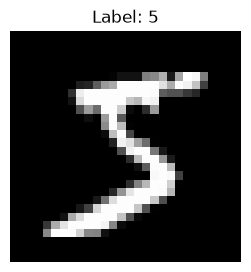

In [3]:
sample_image, sample_label = full_train_dataset[0]

print("이미지 shape:", sample_image.shape)
print("정답 숫자:", sample_label)
print(
    "픽셀값 범위:",
    sample_image.min().item(),
    "~",
    sample_image.max().item(),
)

plt.figure(figsize=(3, 3))
plt.imshow(
    sample_image.squeeze(),
    cmap="gray",
)
plt.title(f"Label: {sample_label}")
plt.axis("off")
plt.show()

## 5. 훈련·검증 데이터 분리

전체 훈련 데이터 60,000개를 다음과 같이 나눕니다.

```text
학습 데이터 55,000개
→ 가중치 학습

검증 데이터 5,000개
→ 매 Epoch의 학습 상태 확인

테스트 데이터 10,000개
→ 학습이 끝난 모델의 최종 평가
```

같은 결과가 나오도록 분할용 난수 기준값을 고정합니다.

In [4]:
split_generator = torch.Generator().manual_seed(
    RANDOM_SEED
)

train_dataset, validation_dataset = random_split(
    full_train_dataset,
    [55_000, 5_000],
    generator=split_generator,
)

print("실제 학습 데이터:", len(train_dataset))
print("검증 데이터:", len(validation_dataset))
print("테스트 데이터:", len(test_dataset))

실제 학습 데이터: 55000
검증 데이터: 5000
테스트 데이터: 10000


## 6. DataLoader 구성

- Batch Size(배치 사이즈): 64
- 학습 데이터: `shuffle=True`
- 검증·테스트 데이터: `shuffle=False`

학습 데이터는 Epoch마다 제시 순서를 섞습니다.
검증과 테스트 데이터는 결과를 일정하게 확인하기 위해 순서를 섞지 않습니다.

In [5]:
BATCH_SIZE = 64
NUMBER_OF_EPOCHS = 5

loader_generator = torch.Generator().manual_seed(
    RANDOM_SEED
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

batch_images, batch_labels = next(
    iter(train_loader)
)

print("배치 이미지 shape:", batch_images.shape)
print("배치 정답 shape:", batch_labels.shape)

배치 이미지 shape: torch.Size([64, 1, 28, 28])
배치 정답 shape: torch.Size([64])


## 7. Batch·Iteration·Epoch 관계

```text
학습 데이터 55,000개
÷ Batch Size 64
→ 한 Epoch에 860번의 Iteration

5 Epoch
→ 최대 4,300번의 가중치 갱신
```

- Batch Size(배치 사이즈): 한 번에 처리하는 데이터 수
- Iteration(이터레이션): 미니배치 한 번 학습
- Epoch(에포크): 전체 학습 데이터를 한 번 학습

In [6]:
iterations_per_epoch = math.ceil(
    len(train_dataset) / BATCH_SIZE
)

maximum_weight_updates = (
    iterations_per_epoch
    * NUMBER_OF_EPOCHS
)

print("에포크당 Iteration:", iterations_per_epoch)
print(
    f"{NUMBER_OF_EPOCHS} Epoch 최대 가중치 갱신:",
    maximum_weight_updates,
)

에포크당 Iteration: 860
5 Epoch 최대 가중치 갱신: 4300


## 8. MLP 모델 구성

```text
입력 이미지 [배치, 1, 28, 28]
→ Flatten
→ [배치, 784]
→ Linear(784, 128)
→ ReLU
→ Dropout(0.2)
→ Linear(128, 10)
→ 숫자별 로짓 10개
```

- `Flatten`: 28×28 이미지를 784개 값으로 펼침
- `Linear(784, 128)`: 784개 픽셀을 128개 특징으로 조합
- `ReLU`: 비선형성 추가
- `Dropout(0.2)`: 학습 중 일부 출력을 무작위로 0으로 설정
- `Linear(128, 10)`: 숫자 0~9의 로짓 10개 출력

In [7]:
torch.manual_seed(RANDOM_SEED)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(128, 10),
).to(device)

print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.2, inplace=False)
  (4): Linear(in_features=128, out_features=10, bias=True)
)


## 9. 모델 출력과 파라미터 수

모델은 이미지 한 장마다 숫자 0~9에 대한 로짓 10개를 출력합니다.

- 입력 shape: `[배치, 1, 28, 28]`
- 출력 shape: `[배치, 10]`
- 전체 학습 파라미터 수: 101,770개

`Flatten`, `ReLU`, `Dropout`에는 학습 파라미터가 없습니다.

In [8]:
model.eval()

with torch.no_grad():
    sample_logits = model(
        batch_images[:4].to(device)
    )

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("모델 출력 shape:", sample_logits.shape)
print(
    "전체 학습 파라미터 수:",
    f"{total_parameters:,}",
)

모델 출력 shape: torch.Size([4, 10])
전체 학습 파라미터 수: 101,770


## 10. 손실함수와 Optimizer

다중분류이므로 `CrossEntropyLoss()`를 사용합니다.

```text
모델의 원시 로짓
→ CrossEntropyLoss
```

모델 마지막에는 Softmax를 넣지 않습니다.
클래스 확률을 확인할 때만 `torch.softmax()`를 사용합니다.

In [9]:
loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
)

print("손실함수:", loss_function)
print("Optimizer:", optimizer.__class__.__name__)

손실함수: CrossEntropyLoss()
Optimizer: Adam


## 11. 공통 평가 함수

검증과 테스트의 계산 절차가 같으므로 하나의 함수로 정리합니다.

함수의 역할:

1. 평가 모드 전환
2. 기울기 계산 중지
3. 평균 손실 계산
4. 정확도 계산

In [10]:
def evaluate_model(data_loader):
    model.eval()

    loss_sum = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)

            loss = loss_function(
                logits,
                labels,
            )

            predictions = logits.argmax(
                dim=1
            )

            loss_sum += (
                loss.item()
                * images.size(0)
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    average_loss = loss_sum / total
    accuracy = correct / total

    return average_loss, accuracy

## 12. 모델 학습

각 Epoch의 흐름:

```text
model.train()
→ 미니배치 입력
→ 로짓 계산
→ 손실 계산
→ 역전파
→ 가중치 갱신
→ 검증 데이터 평가
```

훈련 성능과 검증 성능을 함께 기록합니다.

In [11]:
train_loss_history = []
train_accuracy_history = []

validation_loss_history = []
validation_accuracy_history = []

for epoch in range(
    1,
    NUMBER_OF_EPOCHS + 1,
):
    model.train()

    loss_sum = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # 1. 이전 기울기 초기화
        optimizer.zero_grad()

        # 2. 순전파
        logits = model(images)

        # 3. 손실 계산
        loss = loss_function(
            logits,
            labels,
        )

        # 4. 역전파
        loss.backward()

        # 5. 가중치 갱신
        optimizer.step()

        predictions = logits.argmax(
            dim=1
        )

        loss_sum += (
            loss.item()
            * images.size(0)
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    train_loss = loss_sum / total
    train_accuracy = correct / total

    validation_loss, validation_accuracy = (
        evaluate_model(validation_loader)
    )

    train_loss_history.append(
        train_loss
    )

    train_accuracy_history.append(
        train_accuracy
    )

    validation_loss_history.append(
        validation_loss
    )

    validation_accuracy_history.append(
        validation_accuracy
    )

    print(
        f"Epoch {epoch}/{NUMBER_OF_EPOCHS} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Accuracy {train_accuracy:.4f} | "
        f"Validation Loss {validation_loss:.4f} | "
        f"Validation Accuracy {validation_accuracy:.4f}"
    )

Epoch 1/5 | Train Loss 0.3803 | Train Accuracy 0.8944 | Validation Loss 0.2058 | Validation Accuracy 0.9388
Epoch 2/5 | Train Loss 0.1816 | Train Accuracy 0.9474 | Validation Loss 0.1540 | Validation Accuracy 0.9574
Epoch 3/5 | Train Loss 0.1341 | Train Accuracy 0.9605 | Validation Loss 0.1217 | Validation Accuracy 0.9650
Epoch 4/5 | Train Loss 0.1080 | Train Accuracy 0.9673 | Validation Loss 0.1115 | Validation Accuracy 0.9678
Epoch 5/5 | Train Loss 0.0921 | Train Accuracy 0.9717 | Validation Loss 0.0988 | Validation Accuracy 0.9706


## 13. 손실 변화 확인

훈련 손실과 검증 손실이 함께 감소하는지 확인합니다.

검증 손실이 다시 증가하기 시작하면 과적합 가능성을 점검합니다.

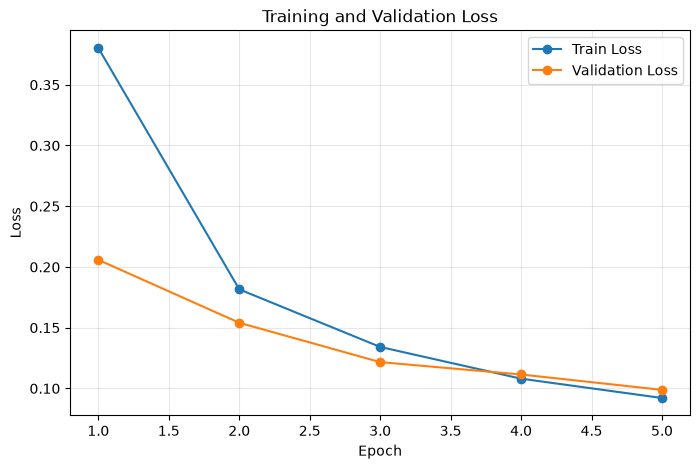

In [12]:
epoch_numbers = range(
    1,
    NUMBER_OF_EPOCHS + 1,
)

plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    train_loss_history,
    marker="o",
    label="Train Loss",
)

plt.plot(
    epoch_numbers,
    validation_loss_history,
    marker="o",
    label="Validation Loss",
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 14. 정확도 변화 확인

훈련 정확도와 검증 정확도의 차이가 지나치게 커지는지 확인합니다.

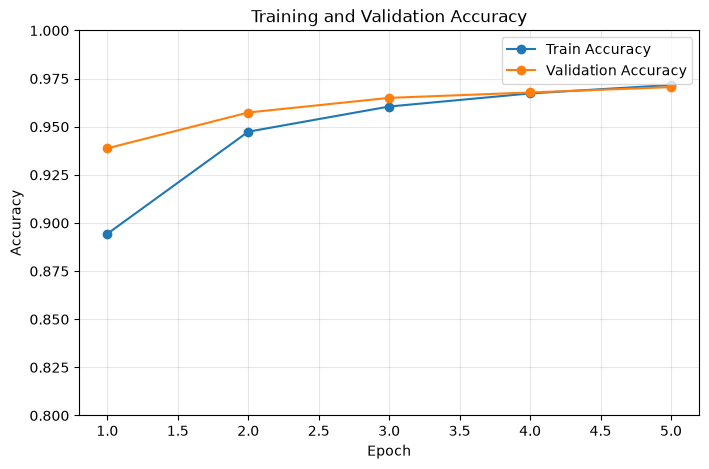

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    train_accuracy_history,
    marker="o",
    label="Train Accuracy",
)

plt.plot(
    epoch_numbers,
    validation_accuracy_history,
    marker="o",
    label="Validation Accuracy",
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.ylim(0.8, 1.0)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 15. 테스트 데이터 최종 평가

학습 설정을 확인한 뒤 테스트 데이터 10,000개로 최종 성능을 측정합니다.

테스트 결과를 보고 같은 실습에서 학습률이나 모델 구조를 다시 선택하지 않습니다.

In [14]:
test_loss, test_accuracy = evaluate_model(
    test_loader
)

print(f"테스트 손실: {test_loss:.4f}")
print(f"테스트 정확도: {test_accuracy:.4f}")
print(
    f"맞힌 이미지 수: "
    f"{int(test_accuracy * len(test_dataset)):,}"
    f" / {len(test_dataset):,}"
)

테스트 손실: 0.0879
테스트 정확도: 0.9746
맞힌 이미지 수: 9,746 / 10,000


## 16. 실제 이미지 예측

테스트 데이터의 첫 번째 미니배치에서 이미지 5개를 확인합니다.

각 이미지에 다음 내용을 표시합니다.

- 실제 정답
- 모델 예측
- 예측 확률

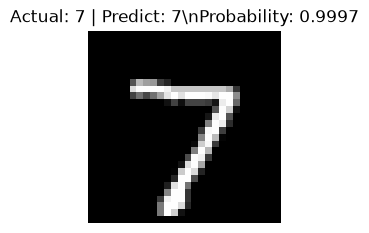

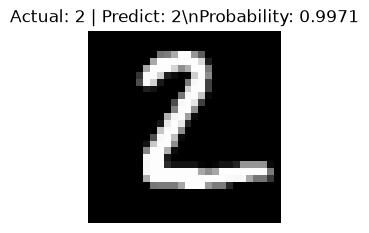

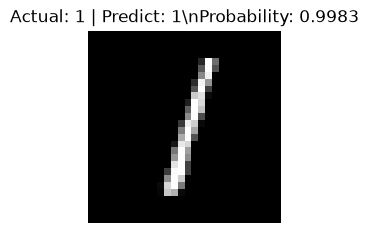

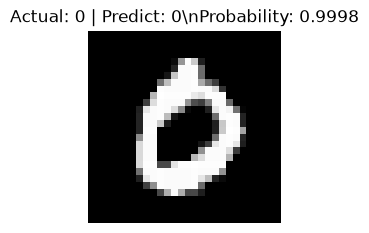

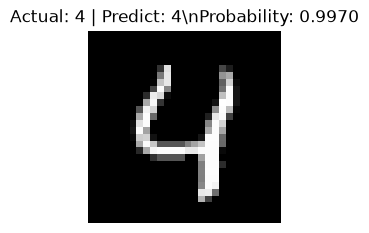

In [15]:
model.eval()

display_images, display_labels = next(
    iter(test_loader)
)

with torch.no_grad():
    display_logits = model(
        display_images.to(device)
    )

    display_probabilities = torch.softmax(
        display_logits,
        dim=1,
    ).cpu()

    display_predictions = display_logits.argmax(
        dim=1
    ).cpu()

for index in range(5):
    actual = display_labels[index].item()
    predicted = display_predictions[index].item()

    confidence = display_probabilities[
        index,
        predicted,
    ].item()

    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(
        display_images[index].squeeze(),
        cmap="gray",
    )
    plt.title(
        f"Actual: {actual} | "
        f"Predict: {predicted}\\n"
        f"Probability: {confidence:.4f}"
    )
    plt.axis("off")
    plt.show()

## 17. 클래스별 확률 확인

첫 번째 테스트 이미지에 대해 숫자 0~9의 확률을 확인합니다.

가장 큰 확률의 위치가 최종 예측 숫자입니다.

In [16]:
first_probabilities = (
    display_probabilities[0]
)

first_prediction = (
    display_predictions[0].item()
)

print(
    "첫 번째 이미지 실제 정답:",
    display_labels[0].item(),
)

print(
    "첫 번째 이미지 예측:",
    first_prediction,
)

print()
print("숫자별 확률:")

for digit, probability in enumerate(
    first_probabilities
):
    print(
        f"{digit}: "
        f"{probability.item():.4f}"
    )

print(
    "확률 합:",
    first_probabilities.sum().item(),
)

첫 번째 이미지 실제 정답: 7
첫 번째 이미지 예측: 7

숫자별 확률:
0: 0.0000
1: 0.0000
2: 0.0000
3: 0.0003
4: 0.0000
5: 0.0000
6: 0.0000
7: 0.9997
8: 0.0000
9: 0.0000
확률 합: 1.0000001192092896


## 18. MLP의 한계
MLP는 이미지를 `Flatten`하여 784개 숫자로 펼칩니다.

```text
2차원 이미지
→ 1차원 벡터
→ 픽셀의 위치 관계를 직접 활용하기 어려움
```

CNN(씨엔엔, 합성곱 신경망)은 이미지의 가로·세로 위치 관계를 유지하면서 특징을 찾습니다.

```text
MLP : MNIST → Flatten → Linear
CNN : MNIST → Conv2d → ReLU → Pooling
```

> **MLP는 픽셀을 긴 벡터로 보고, CNN은 이미지의 지역적 패턴을 학습합니다.**

## 19. 핵심 정리

- MNIST는 28×28 흑백 손글씨 숫자 이미지 데이터입니다.
- `nn.Linear(784, 128)`과 `ReLU`가 은닉층을 구성합니다.
- 최종 클래스는 `argmax(dim=1)`로 선택합니다.